# Waste Classification Assistant — Week 2: Fine-tuning, Class Imbalance & Ablation


Week 1 built a baseline by training **only** a classification head on top of a completely **frozen**
MobileNetV2 — stage one of the standard two-stage transfer-learning workflow. This notebook performs
**stage two**: unfreezing the top of the convolutional base and fine-tuning end-to-end at a very low
learning rate, then testing whether that actually helps.

Three questions drive the work:

| # | Question | Section |
|---|---|---|
| 1 | Does fine-tuning beat the frozen baseline, and by how much? | sections 3 and 4 |
| 2 | Do class weights rescue the rare `trash` class? | section 5 |
| 3 | How much of the base should be unfrozen? | section 6 |

Everything is measured on **the same held-out test set Week 1 created** (`week1/outputs/split.json`),
so the baseline and the fine-tuned models are directly comparable. That split is read, never
regenerated.


## Which references support Week 2

Week 1 established the problem, the dataset and the frozen baseline. This week adds stage two and the
experiments around it, so the relevant sources shift slightly. All citations are APA 7th edition.

| Reference | What it supports here |
|---|---|
| Chollet, F. (2023, June 25). *Transfer learning & fine-tuning* [Keras developer guide]. Keras. | **The fine-tuning recipe itself**: unfreeze the top of the base, keep BatchNormalization frozen, recompile with a rate roughly 100× smaller, then train end-to-end. Section 3 follows it step for step. |
| Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. In *CVPR* (pp. 4510–4520). IEEE. | **What is actually being unfrozen** — MobileNetV2's later inverted-residual blocks carry high-level, task-specific features, which is why they are the candidates for adaptation. Sections 3 and 6. |
| Yang, M., & Thung, G. (2016). *Classification of trash for recyclability status* (CS229 Project Report). Stanford University. | **The class-imbalance problem**: that work documents TrashNet's uneven class distribution, which is why section 5 uses class weights and why sections 4 and 5 judge results by per-class recall and macro-F1 rather than accuracy alone. |
| Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. | **Per-class precision / recall / F1 and macro-F1** — the criterion every experiment here is judged on. Sections 4, 5 and 6. |
| Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In *CVPR* (pp. 248–255). IEEE. | **Why fine-tuning can improve on the baseline**: ImageNet features are generic, and a small, low-rate push adapts them to waste photos instead of destroying them. Section 3. |
| Abadi, M., Barham, P., Chen, J., … Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. In *OSDI '16* (pp. 265–283). USENIX Association. | The `tf.data` pipeline and training loop reused from Week 1. Sections 1 and 3. |
| Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. | Every figure in this notebook. |

The complete list is in section 10.

## 1. Setup

Two decisions shape everything below.

**The Week 1 package is imported, not copied.** `config`, `data_pipeline`, `evaluate` and `utils` come
straight from `week1/`. Both weeks therefore run identical code, which removes any risk of the two
drifting apart and keeps the comparison honest.

**Week 2 writes only to `week2/outputs/`.** In particular it deliberately does *not* reuse
`train_baseline.py`'s callback builder, because that writes its checkpoint to
`week1/outputs/baseline_model.keras` and would silently overwrite the Week 1 deliverable. This
notebook defines its own callbacks pointing at its own output folder.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

# TensorFlow's routine deprecation notices are noisy - quieten them first,
# before tensorflow is imported.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from importlib.metadata import version as _pkg_version

# Imported as IPImage deliberately: the plain name `Image` is easily shadowed by PIL
# (PIL also exports `Image`), and that failure only surfaces much later as a confusing
# "TypeError: 'module' object is not callable".
from IPython.display import HTML, Image as IPImage, display


def find_week1(start: Path) -> Path:
    """Locate week1/ whether the notebook runs from week2/ or from the repo root."""
    for candidate in [start, *start.parents]:
        if (candidate / "week1" / "config.py").exists():
            return candidate / "week1"
        if candidate.name == "week1" and (candidate / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find week1/config.py - is the week2 folder sitting next to week1?"
    )


WEEK1_DIR = find_week1(Path.cwd())
WEEK2_DIR = WEEK1_DIR.parent / "week2"
W1_OUT = WEEK1_DIR / "outputs"          # read-only: Week 1's artefacts
OUT = WEEK2_DIR / "outputs"             # everything Week 2 writes goes here

if str(WEEK1_DIR) not in sys.path:
    sys.path.insert(0, str(WEEK1_DIR))

import config
import data_pipeline as dp
import evaluate as ev
from utils import ensure_dirs, load_json, save_json, silence_tensorflow

silence_tensorflow()
ensure_dirs(OUT)

# --- paths ------------------------------------------------------------------
BASELINE_PATH = W1_OUT / "baseline_model.keras"   # produced by Week 1
SPLIT_PATH = W1_OUT / "split.json"                # the fixed split, reused unchanged


def show_table(headers, rows):
    """Render a table as HTML - easier to read in a notebook than plain markdown."""
    head = "".join(
        f"<th style='padding:5px 12px;border-bottom:2px solid #888;text-align:left'>{h}</th>"
        for h in headers
    )
    body = "".join(
        "<tr>" + "".join(
            f"<td style='padding:4px 12px;border-bottom:1px solid #ddd'>{c}</td>" for c in row
        ) + "</tr>"
        for row in rows
    )
    display(HTML(
        f"<table style='border-collapse:collapse;font-size:13px;margin:6px 0'>{head}{body}</table>"
    ))


def show_figure(path, width=980):
    """Display a figure written to disk, with a clear message if it is missing."""
    path = Path(path)
    if not path.exists():
        print(f"[missing] {path} - run the cell that creates it first.")
        return
    display(IPImage(filename=str(path), width=width))


class EpochTimer(keras.callbacks.Callback):
    """Print how long each epoch takes - the main cost signal when tuning on CPU."""

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        print(
            f"  -> epoch {epoch + 1} took {time.time() - self._t0:.1f}s "
            f"(val_loss={logs.get('val_loss', float('nan')):.4f}, "
            f"val_accuracy={logs.get('val_accuracy', float('nan')):.4f})",
            flush=True,
        )


print(f"week1 dir   : {WEEK1_DIR}")
print(f"week2 dir   : {WEEK2_DIR}")
print(f"tensorflow  : {tf.__version__}")
print(f"keras       : {_pkg_version('keras')}")
print(f"devices     : {[d.device_type for d in tf.config.list_physical_devices()]}")
print(f"baseline    : {BASELINE_PATH.name}  (exists={BASELINE_PATH.exists()})")
print(f"split file  : {SPLIT_PATH.name}  (exists={SPLIT_PATH.exists()})")

if not BASELINE_PATH.exists():
    raise FileNotFoundError(
        f"{BASELINE_PATH} is missing. Run week1/waste_classification_week1.ipynb first - "
        "Week 2 fine-tunes from that checkpoint rather than rebuilding the model."
    )


week1 dir   : d:\pengyuan9869\week1
week2 dir   : d:\pengyuan9869\week2
tensorflow  : 2.15.1
keras       : 2.15.0
devices     : ['CPU']
baseline    : baseline_model.keras  (exists=True)
split file  : split.json  (exists=True)


## 2. Where Week 1 left off, and the split both weeks share

Before changing anything, restate the baseline that everything below is measured against. These
numbers are **read from Week 1's saved metrics**, not recomputed, so the comparison is against the
model that was actually delivered.

One honest caveat, stated up front because it bounds how large an "improvement" it is credible to
claim: the baseline was trained in a separate session. The seed fixes the data split and the
architecture, but TensorFlow's CPU kernels use parallel floating-point reductions and the
augmentation layers draw fresh transforms each epoch, so retraining shifts the baseline's own score by
roughly a point or two. Differences smaller than that should not be over-interpreted.

The split table is printed again because it is the *same* object both weeks use — `split.json` is
loaded, never regenerated, so the held-out test set has not changed since Week 1.

In [2]:
splits = dp.get_or_create_split(SPLIT_PATH)     # loads week1/outputs/split.json verbatim

datasets = {
    name: dp.build_dataset(splits[name], training=(name == "train"), batch_size=config.BATCH_SIZE)
    for name in ("train", "val", "test")
}

print(f"split file : {SPLIT_PATH}")
for name, ds in datasets.items():
    print(f"  {name:<5} {len(splits[name]):>5} images   {len(ds):>3} batches")

show_table(
    ["split", "total", *config.CLASS_NAMES],
    [[name, len(splits[name]), *[sum(1 for _, y in splits[name] if config.CLASS_NAMES[y] == c)
                                 for c in config.CLASS_NAMES]]
     for name in ("train", "val", "test")],
)

# --- registry filled in as models are trained ---------------------------------
RESULTS = {}   # tag -> {"val": metrics, "test": metrics}
MODELS = {}    # tag -> trained keras model
PROBS = {}     # tag -> {"val": (y_true, y_prob), "test": (y_true, y_prob)}

BASELINE_TAG = "baseline (frozen base)"
RESULTS[BASELINE_TAG] = {name: load_json(W1_OUT / f"metrics_{name}.json") for name in ("val", "test")}
for name in ("val", "test"):
    RESULTS[BASELINE_TAG][name]["misclassified_count"] = int(
        (np.asarray(RESULTS[BASELINE_TAG][name]["y_true"])
         != np.asarray(RESULTS[BASELINE_TAG][name]["y_pred"])).sum()
    )

show_table(
    ["split", "accuracy", "balanced acc.", "macro F1", "weighted F1", "errors"],
    [[name, f"{m['accuracy']:.4f}", f"{m['balanced_accuracy']:.4f}", f"{m['macro_f1']:.4f}",
      f"{m['weighted_f1']:.4f}", m["misclassified_count"]]
     for name, m in RESULTS[BASELINE_TAG].items()],
)
show_table(
    ["class", "precision", "recall", "F1", "support"],
    [[c, f"{v['precision']:.3f}", f"{v['recall']:.3f}", f"{v['f1']:.3f}", v["support"]]
     for c, v in RESULTS[BASELINE_TAG]["test"]["per_class"].items()],
)

split file : d:\pengyuan9869\week1\outputs\split.json
  train  1769 images    56 batches
  val     379 images    12 batches
  test    379 images    12 batches


train,1769,283,351,286,416,338,95
val,379,60,75,62,89,72,21
test,379,60,75,62,89,72,21


val,0.8364,0.8232,0.8118,0.8382,62
test,0.8021,0.7684,0.7684,0.8025,75


cardboard,0.948,0.917,0.932,60
glass,0.864,0.680,0.761,75
metal,0.757,0.903,0.824,62
paper,0.904,0.843,0.872,89
plastic,0.663,0.792,0.722,72
trash,0.526,0.476,0.500,21


## 3. Stage two: fine-tuning the top of the base

Week 1 trained **only** the classification head — stage one. Stage two **unfreezes the top of the
convolutional base and continues training end-to-end**, so the later blocks can adapt from generic
ImageNet features to waste photos (Chollet, 2023).

Three details are deliberate:

- **The top 20 layers are unfrozen, out of 154.** MobileNetV2's early blocks (Sandler et al., 2018)
  detect generic structure — edges, colour gradients, simple textures — which transfers to almost any
  image task, while its later blocks encode higher-level, more task-specific patterns. Those later
  blocks are the candidates for adaptation, and "the top 20" is the configuration the project plan
  specifies.
  It is worth being precise about what "20 of 154" means in practice: the unfrozen tail contains the
  parameter-heavy inverted-residual blocks, so this reopens **roughly half the network**, not a thin
  sliver. The model cell below prints the exact figure. Whether that much unfreezing is wise on 1,769
  training images is an empirical question rather than an assumption — section 6 tests it by comparing 10,
  20 and all.
- **The learning rate is 100× smaller (`1e-5` versus Week 1's `1e-3`).**
- **BatchNormalization layers stay frozen even inside the unfrozen block.** Because the base is called
  with `training=False`, its moving statistics are never updated — so allowing only the scale and
  offset to move would let the normalisation drift underneath fixed statistics. The Keras guide
  recommends exactly this.


In [3]:
FINETUNE_LAYERS = 20      # how many of the base's layers to unfreeze
FINETUNE_LR = 1e-5        # 100x smaller than the Week 1 head-training rate
FINETUNE_EPOCHS = 10
PATIENCE = 3


def find_base(model):
    """Return the MobileNetV2 sub-model inside the model Week 1 saved."""
    for layer in model.layers:
        if layer.name.startswith("mobilenetv2"):
            return layer
    raise LookupError("No MobileNetV2 layer found in the saved model.")


def make_model(unfreeze_last=FINETUNE_LAYERS, learning_rate=FINETUNE_LR, weights=BASELINE_PATH):
    """Load the Week 1 checkpoint and re-open the top `unfreeze_last` base layers."""
    model = keras.models.load_model(weights)
    base = find_base(model)
    base.trainable = True

    if unfreeze_last is None:                  # unfreeze the whole base
        for layer in base.layers:
            layer.trainable = True
    elif unfreeze_last <= 0:                   # control case: nothing unfrozen
        for layer in base.layers:
            layer.trainable = False
    else:
        for layer in base.layers[:-unfreeze_last]:
            layer.trainable = False
        for layer in base.layers[-unfreeze_last:]:
            layer.trainable = True

    # Keep BatchNormalization frozen everywhere. With training=False its moving
    # statistics are never updated, so learning only its scale/offset would
    # destabilise the block it normalises.
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model, base


def count_params(model):
    """(trainable, total) parameter counts."""
    trainable = sum(int(tf.size(w)) for w in model.trainable_weights)
    return trainable, int(model.count_params())


def build_callbacks(tag, patience=PATIENCE):
    """Week 2's own callbacks, writing into week2/outputs - never over week1's artefacts."""
    return [
        EpochTimer(),
        keras.callbacks.ModelCheckpoint(
            filepath=str(OUT / f"{tag}_model.keras"),
            monitor="val_loss", mode="min", save_best_only=True, verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=patience,
            restore_best_weights=True, verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1,
        ),
        keras.callbacks.CSVLogger(str(OUT / f"{tag}_log.csv"), append=False),
    ]


def plot_history(history, path, title):
    """Accuracy and loss curves, saved to disk."""
    epochs = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    axes[0].plot(epochs, history["accuracy"], "o-", label="train")
    axes[0].plot(epochs, history["val_accuracy"], "s-", label="validation")
    axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch")
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, history["loss"], "o-", label="train")
    axes[1].plot(epochs, history["val_loss"], "s-", label="validation")
    axes[1].set_title("Loss"); axes[1].set_xlabel("epoch")
    axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(path, dpi=140); plt.close(fig)
    print(f"  curves -> {path}")


ft_model, ft_base = make_model()
ft_trainable, ft_total = count_params(ft_model)

show_table(
    ["setting", "value"],
    [
        ["base layers (total)", len(ft_base.layers)],
        ["base layers unfrozen", FINETUNE_LAYERS],
        ["learning rate", f"{FINETUNE_LR:g}   (Week 1 head training used {config.LEARNING_RATE:g})"],
        ["trainable parameters", f"{ft_trainable:,}"],
        ["total parameters", f"{ft_total:,}"],
        ["trainable share", f"{ft_trainable / ft_total:.2%}"],
    ],
)
print("The trainable share is far higher than Week 1's 0.34% - that is the whole point of stage two,")
print("and it is also why the learning rate has to be much smaller.")

base layers (total),154
base layers unfrozen,20
learning rate,1e-05 (Week 1 head training used 0.001)
trainable parameters,"1,202,566"
total parameters,"2,265,670"
trainable share,53.08%


The trainable share is far higher than Week 1's 0.34% - that is the whole point of stage two,
and it is also why the learning rate has to be much smaller.


Epoch 1/10
  -> epoch 1 took 21.6s (val_loss=0.4131, val_accuracy=0.8575)

Epoch 1: val_loss improved from inf to 0.41307, saving model to d:\pengyuan9869\week2\outputs\finetuned_model.keras
56/56 - 22s - loss: 0.3780 - accuracy: 0.8609 - val_loss: 0.4131 - val_accuracy: 0.8575 - lr: 1.0000e-05 - 22s/epoch - 400ms/step
Epoch 2/10
  -> epoch 2 took 12.6s (val_loss=0.4072, val_accuracy=0.8654)

Epoch 2: val_loss improved from 0.41307 to 0.40716, saving model to d:\pengyuan9869\week2\outputs\finetuned_model.keras
56/56 - 13s - loss: 0.3336 - accuracy: 0.8790 - val_loss: 0.4072 - val_accuracy: 0.8654 - lr: 1.0000e-05 - 13s/epoch - 235ms/step
Epoch 3/10
  -> epoch 3 took 12.1s (val_loss=0.4195, val_accuracy=0.8470)

Epoch 3: val_loss did not improve from 0.40716
56/56 - 12s - loss: 0.3201 - accuracy: 0.8824 - val_loss: 0.4195 - val_accuracy: 0.8470 - lr: 1.0000e-05 - 12s/epoch - 216ms/step
Epoch 4/10
  -> epoch 4 took 14.2s (val_loss=0.4057, val_accuracy=0.8602)

Epoch 4: val_loss improved 

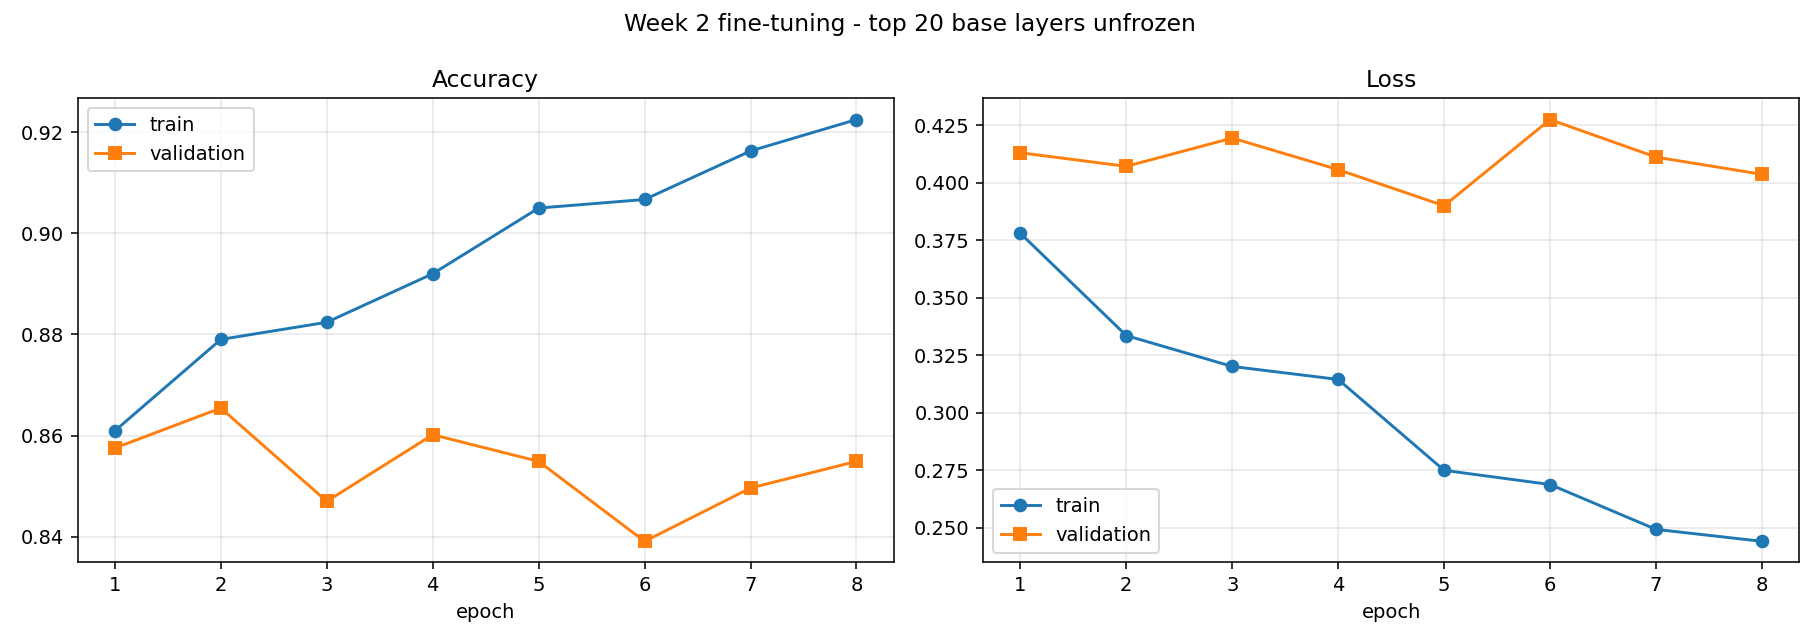

In [4]:
t0 = time.time()
history_ft = ft_model.fit(
    datasets["train"],
    validation_data=datasets["val"],
    epochs=FINETUNE_EPOCHS,
    callbacks=build_callbacks("finetuned"),
    verbose=2,
)
ft_seconds = time.time() - t0

ft_history = {k: [float(x) for x in v] for k, v in history_ft.history.items()}
save_json(OUT / "history_finetuned.json", {
    "config": {
        "unfreeze_last": FINETUNE_LAYERS,
        "learning_rate": FINETUNE_LR,
        "epochs_requested": FINETUNE_EPOCHS,
        "epochs_run": len(ft_history["loss"]),
        "batch_size": config.BATCH_SIZE,
        "seed": config.SEED,
        "base_checkpoint": BASELINE_PATH.name,
    },
    "history": ft_history,
    "training_seconds": round(ft_seconds, 1),
})

print(f"\nfine-tuning wall-clock: {ft_seconds / 60:.1f} min on CPU")
plot_history(ft_history, OUT / "curves_finetuned.png",
             "Week 2 fine-tuning - top 20 base layers unfrozen")
show_figure(OUT / "curves_finetuned.png")

## 4. Does fine-tuning actually help?

Judged on the **held-out test set**, which has never been used for tuning in either week.

Four views are reported rather than one, because TrashNet is imbalanced: overall accuracy, macro-F1
(every class weighted equally, so the 21 `trash` test images count as much as the 89 `paper` ones),
balanced accuracy, and per-class recall. The last of these is what shows *which* classes the
fine-tuning helped.

 The test set has only 379 images. With accuracy near 0.80 the
standard error of a single accuracy figure is

$$\mathrm{SE}=\sqrt{\frac{p(1-p)}{n}}=\sqrt{\frac{0.80 \times 0.20}{379}}\approx 2.1\ \text{percentage points}$$

so the 95% interval around any accuracy reported here is roughly **±4 points**. Every between-model
difference measured in this notebook is well inside that interval, and re-running the identical code
moves these figures by more than the models differ from one another. The honest reading is therefore
**"no difference detected at this test-set size"** — not "X is better", and not "X is useless".

That is why the per-class table below reports the change in **number of images** as well as in rates:
on 379 images a rate change of 0.05 is a handful of photographs, and counting them is what keeps the
conclusion honest. Resolving a one- or two-point difference on this dataset would need cross-validation
or a substantially larger test set — a limitation of the data, not of the comparison.

**A specific outcome to watch for.** Accuracy can rise while macro-F1 does **not**. That happens when
the improvement lands on the large classes and any regression lands on the small one — exactly the
pattern the imbalance argument predicts — and it would mean the headline accuracy flatters the model.

In [5]:
def metrics_for(model, split):
    """Metrics plus raw predictions for one split."""
    y_true, y_prob = ev.predict(model, datasets[split])
    metrics = ev.compute_metrics(y_true, y_prob)
    metrics["misclassified_count"] = int((y_true != y_prob.argmax(axis=1)).sum())
    return metrics, y_true, y_prob


def evaluate_model(model, tag):
    """Evaluate on val and test, and register the results under `tag`."""
    MODELS[tag] = model
    RESULTS[tag] = {}
    PROBS[tag] = {}
    for split in ("val", "test"):
        metrics, y_true, y_prob = metrics_for(model, split)
        RESULTS[tag][split] = metrics
        PROBS[tag][split] = (y_true, y_prob)
    return RESULTS[tag]


FINETUNED_TAG = "fine-tuned (top 20)"
evaluate_model(ft_model, FINETUNED_TAG)


def comparison_rows(tags, splits_to_show=("val", "test")):
    rows = []
    for tag in tags:
        for split in splits_to_show:
            m = RESULTS[tag][split]
            rows.append([tag, split, f"{m['accuracy']:.4f}", f"{m['balanced_accuracy']:.4f}",
                         f"{m['macro_f1']:.4f}", f"{m['weighted_f1']:.4f}",
                         m["misclassified_count"]])
    return rows


show_table(["model", "split", "accuracy", "balanced acc.", "macro F1", "weighted F1", "errors"],
           comparison_rows([BASELINE_TAG, FINETUNED_TAG]))

base_test = RESULTS[BASELINE_TAG]["test"]
ft_test = RESULTS[FINETUNED_TAG]["test"]
show_table(
    ["test metric", "baseline", "fine-tuned", "change"],
    [[label, f"{base_test[key]:.4f}", f"{ft_test[key]:.4f}", f"{ft_test[key] - base_test[key]:+.4f}"]
     for label, key in [("accuracy", "accuracy"),
                        ("balanced accuracy", "balanced_accuracy"),
                        ("macro F1", "macro_f1"),
                        ("weighted F1", "weighted_f1")]],
)

baseline (frozen base),val,0.8364,0.8232,0.8118,0.8382,62
baseline (frozen base),test,0.8021,0.7684,0.7684,0.8025,75
fine-tuned (top 20),val,0.8549,0.8295,0.8262,0.8546,55
fine-tuned (top 20),test,0.8021,0.7570,0.7575,0.8004,75


accuracy,0.8021,0.8021,+0.0000
balanced accuracy,0.7684,0.7570,-0.0114
macro F1,0.7684,0.7575,-0.0109
weighted F1,0.8025,0.8004,-0.0021


cardboard,60,0.917,0.950,+0.033,+2,-0.035
glass,75,0.680,0.773,+0.093,+7,+0.033
metal,62,0.903,0.790,-0.113,-7,-0.027
paper,89,0.843,0.787,-0.056,-5,-0.018
plastic,72,0.792,0.861,+0.069,+5,+0.049
trash,21,0.476,0.381,-0.095,-2,-0.068


net change in correctly classified test images: +0   (errors 75 -> 75)


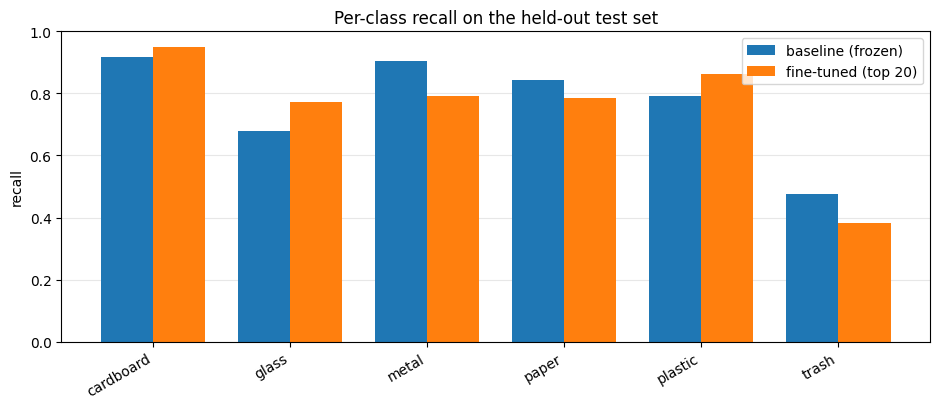

In [6]:
def images_gained(base_metrics, new_metrics, cls):
    """Images of this class that moved from wrong to right (+), or the reverse (-)."""
    support = base_metrics["per_class"][cls]["support"]
    return round(support * (new_metrics["per_class"][cls]["recall"]
                            - base_metrics["per_class"][cls]["recall"]))


show_table(
    ["class", "test support", "baseline recall", "fine-tuned recall",
     "recall change", "images gained/lost", "F1 change"],
    [[c, base_test["per_class"][c]["support"],
      f"{base_test['per_class'][c]['recall']:.3f}",
      f"{ft_test['per_class'][c]['recall']:.3f}",
      f"{ft_test['per_class'][c]['recall'] - base_test['per_class'][c]['recall']:+.3f}",
      f"{images_gained(base_test, ft_test, c):+d}",
      f"{ft_test['per_class'][c]['f1'] - base_test['per_class'][c]['f1']:+.3f}"]
     for c in config.CLASS_NAMES],
)

net_images = sum(images_gained(base_test, ft_test, c) for c in config.CLASS_NAMES)
print(f"net change in correctly classified test images: {net_images:+d}   "
      f"(errors {base_test['misclassified_count']} -> {ft_test['misclassified_count']})")

x = np.arange(len(config.CLASS_NAMES))
width = 0.38
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(x - width / 2, [base_test["per_class"][c]["recall"] for c in config.CLASS_NAMES],
       width, label="baseline (frozen)")
ax.bar(x + width / 2, [ft_test["per_class"][c]["recall"] for c in config.CLASS_NAMES],
       width, label="fine-tuned (top 20)")
ax.set_xticks(x)
ax.set_xticklabels(config.CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("recall")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_title("Per-class recall on the held-out test set")
ax.legend()
plt.tight_layout()
fig.savefig(OUT / "per_class_recall_comparison.png", dpi=140)
plt.show()

## 5. Experiment: class weights for the rare class

The baseline's weakest class is consistently the smallest one. TrashNet is imbalanced by roughly 4.3×
(137 `trash` against 594 `paper`), and a loss that averages over examples simply cares less about those
137 images.

The standard remedy is **balanced class weights**, so a mistake on a rare class costs proportionally
more. The `balanced` weighting is

$$w_c = \frac{N}{C \cdot n_c}$$

where $N$ is the number of training images, $C$ the number of classes and $n_c$ the count for class
$c$. Week 1's `data_pipeline.compute_class_weight` implements exactly that, so it is reused rather
than rewritten.

**What to watch for:** re-weighting the loss does not create information — it moves the decision
boundary, so something else has to pay for it. The cost can show up as lower precision on the rare
class (if it starts being predicted too eagerly) or, just as often, as lower recall on whichever class
the rare one starts stealing from. So this section reads precision *and* recall per class plus
macro-F1, and checks whether the weighting helped the rare class **net of its effect everywhere
else** — total accuracy is a poor guide, being dominated by the majority classes by construction.

In [7]:
class_weight = dp.compute_class_weight(splits["train"])
train_counts = {c: sum(1 for _, y in splits["train"] if config.CLASS_NAMES[y] == c)
                for c in config.CLASS_NAMES}

show_table(
    ["class", "train images", "share of train", "class weight"],
    [[c, train_counts[c], f"{train_counts[c] / len(splits['train']):.1%}", f"{class_weight[i]:.3f}"]
     for i, c in enumerate(config.CLASS_NAMES)],
)
print("A weight above 1 means the class is rarer than average and its mistakes count for more.")

cardboard,283,16.0%,1.042
glass,351,19.8%,0.840
metal,286,16.2%,1.031
paper,416,23.5%,0.709
plastic,338,19.1%,0.872
trash,95,5.4%,3.104


A weight above 1 means the class is rarer than average and its mistakes count for more.


Epoch 1/10
  -> epoch 1 took 22.0s (val_loss=0.4434, val_accuracy=0.8417)

Epoch 1: val_loss improved from inf to 0.44338, saving model to d:\pengyuan9869\week2\outputs\finetuned_classweight_model.keras
56/56 - 23s - loss: 0.3859 - accuracy: 0.8638 - val_loss: 0.4434 - val_accuracy: 0.8417 - lr: 1.0000e-05 - 23s/epoch - 412ms/step
Epoch 2/10
  -> epoch 2 took 12.5s (val_loss=0.4803, val_accuracy=0.8364)

Epoch 2: val_loss did not improve from 0.44338
56/56 - 13s - loss: 0.3717 - accuracy: 0.8666 - val_loss: 0.4803 - val_accuracy: 0.8364 - lr: 1.0000e-05 - 13s/epoch - 224ms/step
Epoch 3/10
  -> epoch 3 took 11.9s (val_loss=0.4755, val_accuracy=0.8391)

Epoch 3: val_loss did not improve from 0.44338

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
56/56 - 12s - loss: 0.3363 - accuracy: 0.8779 - val_loss: 0.4755 - val_accuracy: 0.8391 - lr: 1.0000e-05 - 12s/epoch - 212ms/step
Epoch 4/10
  -> epoch 4 took 12.0s (val_loss=0.4454, val_accuracy=0.8470)

Epoch 4: va

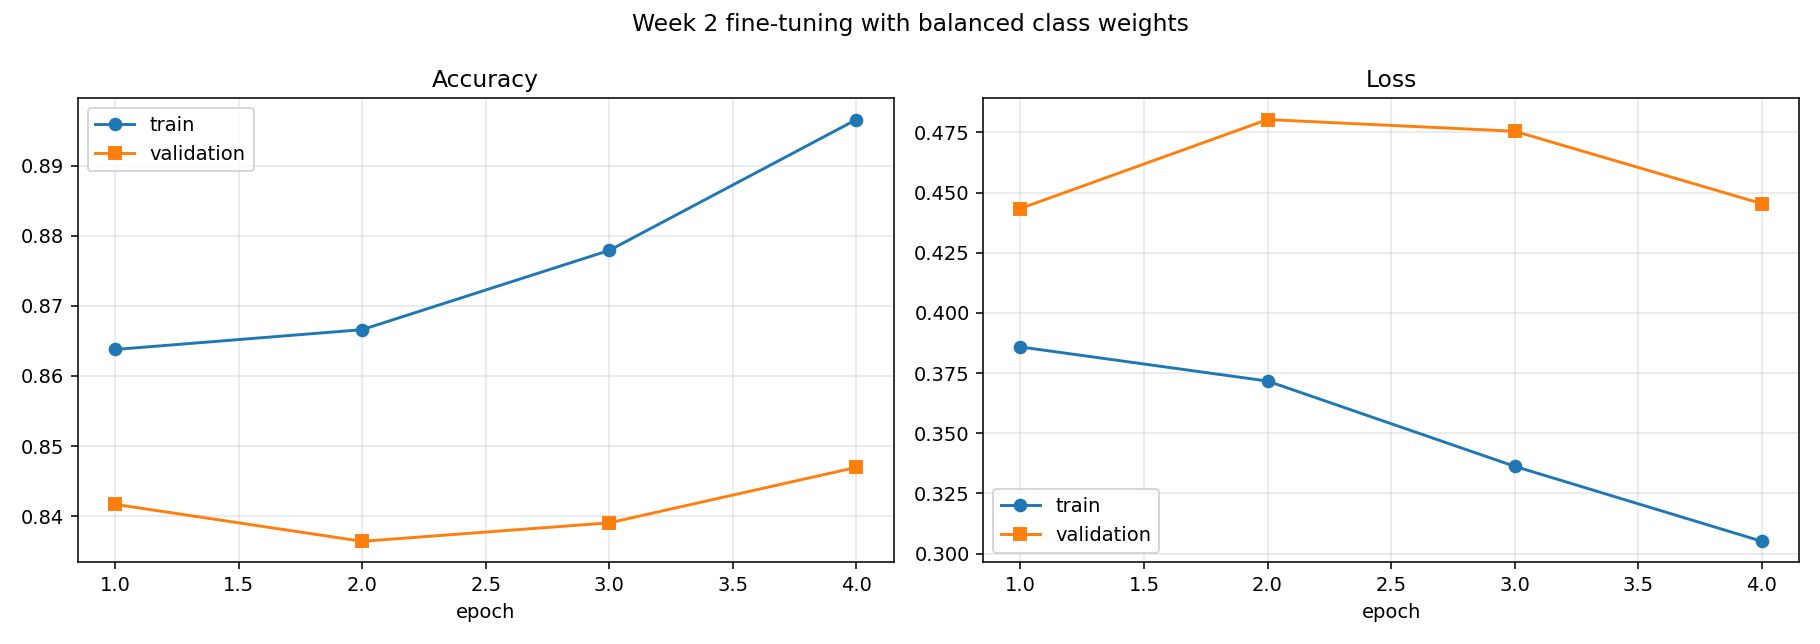

In [8]:
cw_model, cw_base = make_model()

t0 = time.time()
history_cw = cw_model.fit(
    datasets["train"],
    validation_data=datasets["val"],
    epochs=FINETUNE_EPOCHS,
    class_weight=class_weight,
    callbacks=build_callbacks("finetuned_classweight"),
    verbose=2,
)
cw_seconds = time.time() - t0

cw_history = {k: [float(x) for x in v] for k, v in history_cw.history.items()}
save_json(OUT / "history_classweight.json", {
    "config": {
        "unfreeze_last": FINETUNE_LAYERS,
        "learning_rate": FINETUNE_LR,
        "epochs_requested": FINETUNE_EPOCHS,
        "epochs_run": len(cw_history["loss"]),
        "class_weight": {config.CLASS_NAMES[k]: round(float(v), 4) for k, v in class_weight.items()},
        "seed": config.SEED,
    },
    "history": cw_history,
    "training_seconds": round(cw_seconds, 1),
})

print(f"\nclass-weighted run wall-clock: {cw_seconds / 60:.1f} min on CPU")
plot_history(cw_history, OUT / "curves_classweight.png",
             "Week 2 fine-tuning with balanced class weights")
show_figure(OUT / "curves_classweight.png")

In [9]:
CLASS_WEIGHT_TAG = "fine-tuned + class weights"
evaluate_model(cw_model, CLASS_WEIGHT_TAG)

TAGS = [BASELINE_TAG, FINETUNED_TAG, CLASS_WEIGHT_TAG]

show_table(
    ["model", "test accuracy", "balanced acc.", "macro F1", "weighted F1", "errors"],
    [[t, f"{RESULTS[t]['test']['accuracy']:.4f}", f"{RESULTS[t]['test']['balanced_accuracy']:.4f}",
      f"{RESULTS[t]['test']['macro_f1']:.4f}", f"{RESULTS[t]['test']['weighted_f1']:.4f}",
      RESULTS[t]["test"]["misclassified_count"]] for t in TAGS],
)

show_table(
    ["class", "support", *TAGS],
    [[c, base_test["per_class"][c]["support"],
      *[f"{RESULTS[t]['test']['per_class'][c]['recall']:.3f}" for t in TAGS]]
     for c in config.CLASS_NAMES],
)
print("(values are per-class recall on the held-out test set)")

save_json(OUT / "comparison.json", {
    "test_set_size": len(splits["test"]),
    "models": {
        t: {k: {kk: vv for kk, vv in v.items() if kk not in ("y_true", "y_pred", "y_conf")}
            for k, v in RESULTS[t].items()}
        for t in TAGS
    },
})
print(f"\ncomparison table saved -> {OUT / 'comparison.json'}")

baseline (frozen base),0.8021,0.7684,0.7684,0.8025,75
fine-tuned (top 20),0.8021,0.7570,0.7575,0.8004,75
fine-tuned + class weights,0.7916,0.7605,0.7566,0.7917,79


cardboard,60,0.917,0.950,0.933
glass,75,0.680,0.773,0.627
metal,62,0.903,0.790,0.887
paper,89,0.843,0.787,0.820
plastic,72,0.792,0.861,0.819
trash,21,0.476,0.381,0.476


(values are per-class recall on the held-out test set)

comparison table saved -> d:\pengyuan9869\week2\outputs\comparison.json


## 6. Ablation: how much of the base should be unfrozen?

Fine-tuning has one *structural* knob — how many of the base's layers to reopen — and one *tuning*
knob, the learning rate. This section sweeps the structural knob at a fixed rate.

The grid is deliberately **small**: every extra configuration costs real CPU time, and a short grid
that actually gets interpreted is worth more than a large one that is only skimmed.

**The hypothesis being tested.** Section 3 reopened roughly half the network in parameters, so it is fair to
ask whether that much capacity is helping or simply overfitting 1,769 training images — the training
curves in sections 3 and 5 both show training accuracy well above validation accuracy. The natural guess is
that unfreezing *less* would generalise better. That guess is not asserted here: the table below is
what settles it, and the answer should be reported whichever way it comes out.

Each configuration is trained for fewer epochs than the main runs in sections 3–5, so the numbers here are
for **ranking the configurations against each other**, not for comparison with the section 4 results.
Configurations are evaluated without being registered in the model registry, precisely so they cannot
be mistaken for a 10-epoch result.




===== unfreeze top 10   (lr=1e-05, 5 epochs) =====
Epoch 1/5
  -> epoch 1 took 16.2s (val_loss=0.4443, val_accuracy=0.8417)

Epoch 1: val_loss improved from inf to 0.44426, saving model to d:\pengyuan9869\week2\outputs\ablation_top10_model.keras
56/56 - 17s - loss: 0.3666 - accuracy: 0.8745 - val_loss: 0.4443 - val_accuracy: 0.8417 - lr: 1.0000e-05 - 17s/epoch - 300ms/step
Epoch 2/5
  -> epoch 2 took 11.3s (val_loss=0.4325, val_accuracy=0.8496)

Epoch 2: val_loss improved from 0.44426 to 0.43246, saving model to d:\pengyuan9869\week2\outputs\ablation_top10_model.keras
56/56 - 12s - loss: 0.3656 - accuracy: 0.8598 - val_loss: 0.4325 - val_accuracy: 0.8496 - lr: 1.0000e-05 - 12s/epoch - 212ms/step
Epoch 3/5
  -> epoch 3 took 14.2s (val_loss=0.4325, val_accuracy=0.8417)

Epoch 3: val_loss did not improve from 0.43246
56/56 - 14s - loss: 0.3500 - accuracy: 0.8779 - val_loss: 0.4325 - val_accuracy: 0.8417 - lr: 1.0000e-05 - 14s/epoch - 254ms/step
Epoch 4/5
  -> epoch 4 took 14.7s (val_loss

top 10,"733,126",32.36%,0.8443,0.8226,0.8047,0.7595
top 20,"1,202,566",53.08%,0.8443,0.8168,0.8100,0.7638
all,"2,197,446",96.99%,0.8470,0.8207,0.8127,0.7711


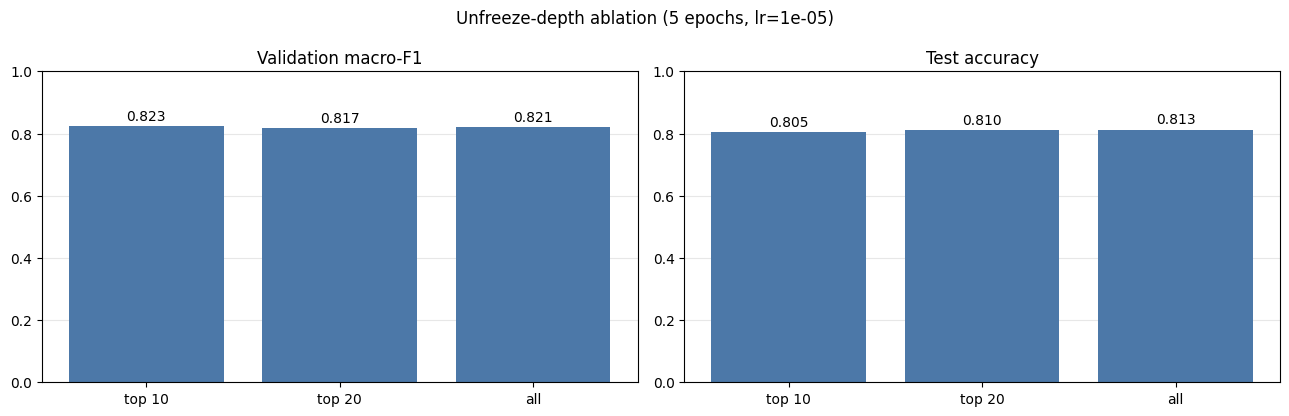

In [ ]:
RUN_ABLATION = True
ABLATION_DEPTHS = [10, 20, None]     # None = unfreeze the whole base
ABLATION_LR = 1e-5
ABLATION_EPOCHS = 5                  # shorter than the main runs, to keep the grid affordable

ablation_runs = []

if RUN_ABLATION:
    for depth in ABLATION_DEPTHS:
        label = "all" if depth is None else f"top {depth}"
        print(f"\n===== unfreeze {label}   (lr={ABLATION_LR:g}, {ABLATION_EPOCHS} epochs) =====")
        run_model, run_base = make_model(unfreeze_last=depth, learning_rate=ABLATION_LR)
        run_trainable, run_total = count_params(run_model)

        run_model.fit(
            datasets["train"], validation_data=datasets["val"], epochs=ABLATION_EPOCHS,
            callbacks=build_callbacks(f"ablation_{label.replace(' ', '')}"), verbose=2,
        )

        val_m, _, _ = metrics_for(run_model, "val")
        test_m, _, _ = metrics_for(run_model, "test")
        ablation_runs.append({
            "unfreeze": label,
            "unfreeze_layers": depth,
            "learning_rate": ABLATION_LR,
            "epochs": ABLATION_EPOCHS,
            "trainable_params": run_trainable,
            "trainable_share": round(run_trainable / run_total, 4),
            "val_accuracy": round(val_m["accuracy"], 4),
            "val_macro_f1": round(val_m["macro_f1"], 4),
            "test_accuracy": round(test_m["accuracy"], 4),
            "test_macro_f1": round(test_m["macro_f1"], 4),
        })
        del run_model

    save_json(OUT / "ablation_results.json", {
        "learning_rate": ABLATION_LR,
        "epochs": ABLATION_EPOCHS,
        "note": "Short runs, for ranking configurations only - not comparable to the 10-epoch runs in sections 4 and 5.",
        "runs": ablation_runs,
    })

if ablation_runs:
    show_table(
        ["unfreeze", "trainable params", "share", "val acc", "val macro F1", "test acc", "test macro F1"],
        [[r["unfreeze"], f"{r['trainable_params']:,}", f"{r['trainable_share']:.2%}",
          f"{r['val_accuracy']:.4f}", f"{r['val_macro_f1']:.4f}",
          f"{r['test_accuracy']:.4f}", f"{r['test_macro_f1']:.4f}"] for r in ablation_runs],
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    labels = [r["unfreeze"] for r in ablation_runs]
    for ax, key, title in ((axes[0], "val_macro_f1", "Validation macro-F1"),
                           (axes[1], "test_accuracy", "Test accuracy")):
        bars = ax.bar(labels, [r[key] for r in ablation_runs], color="#4C78A8")
        ax.bar_label(bars, fmt="%.3f", padding=2)
        ax.set_title(title)
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
    fig.suptitle(f"Unfreeze-depth ablation ({ABLATION_EPOCHS} epochs, lr={ABLATION_LR:g})")
    fig.tight_layout()
    fig.savefig(OUT / "ablation_unfreeze_depth.png", dpi=140)
    plt.show()
else:
    print("Ablation skipped (RUN_ABLATION = False).")

## 7. Error analysis on the best model

Everything so far has been quantitative. This section looks at *what* the remaining errors actually
are, which is what turns a number into something actionable.

Two things are examined:

1. **The confusion structure** — which class is being mistaken for which, ranked by frequency.
2. **The most confident mistakes** — images the model got wrong while being sure. Sorting by
   confidence matters: low-confidence errors are often genuinely ambiguous photos, whereas
   high-confidence errors mean the model has latched onto the wrong visual cue, and those are the
   problems worth fixing.

The model analysed is whichever registered model scored the best **test macro-F1**, and the weakest
class is then broken down in detail — that is the targeted analysis the plan asks for in task 2.5.

best registered model by test macro-F1: fine-tuned (top 20)
  confusion matrix -> d:\pengyuan9869\week2\outputs\confusion_matrix_best.png


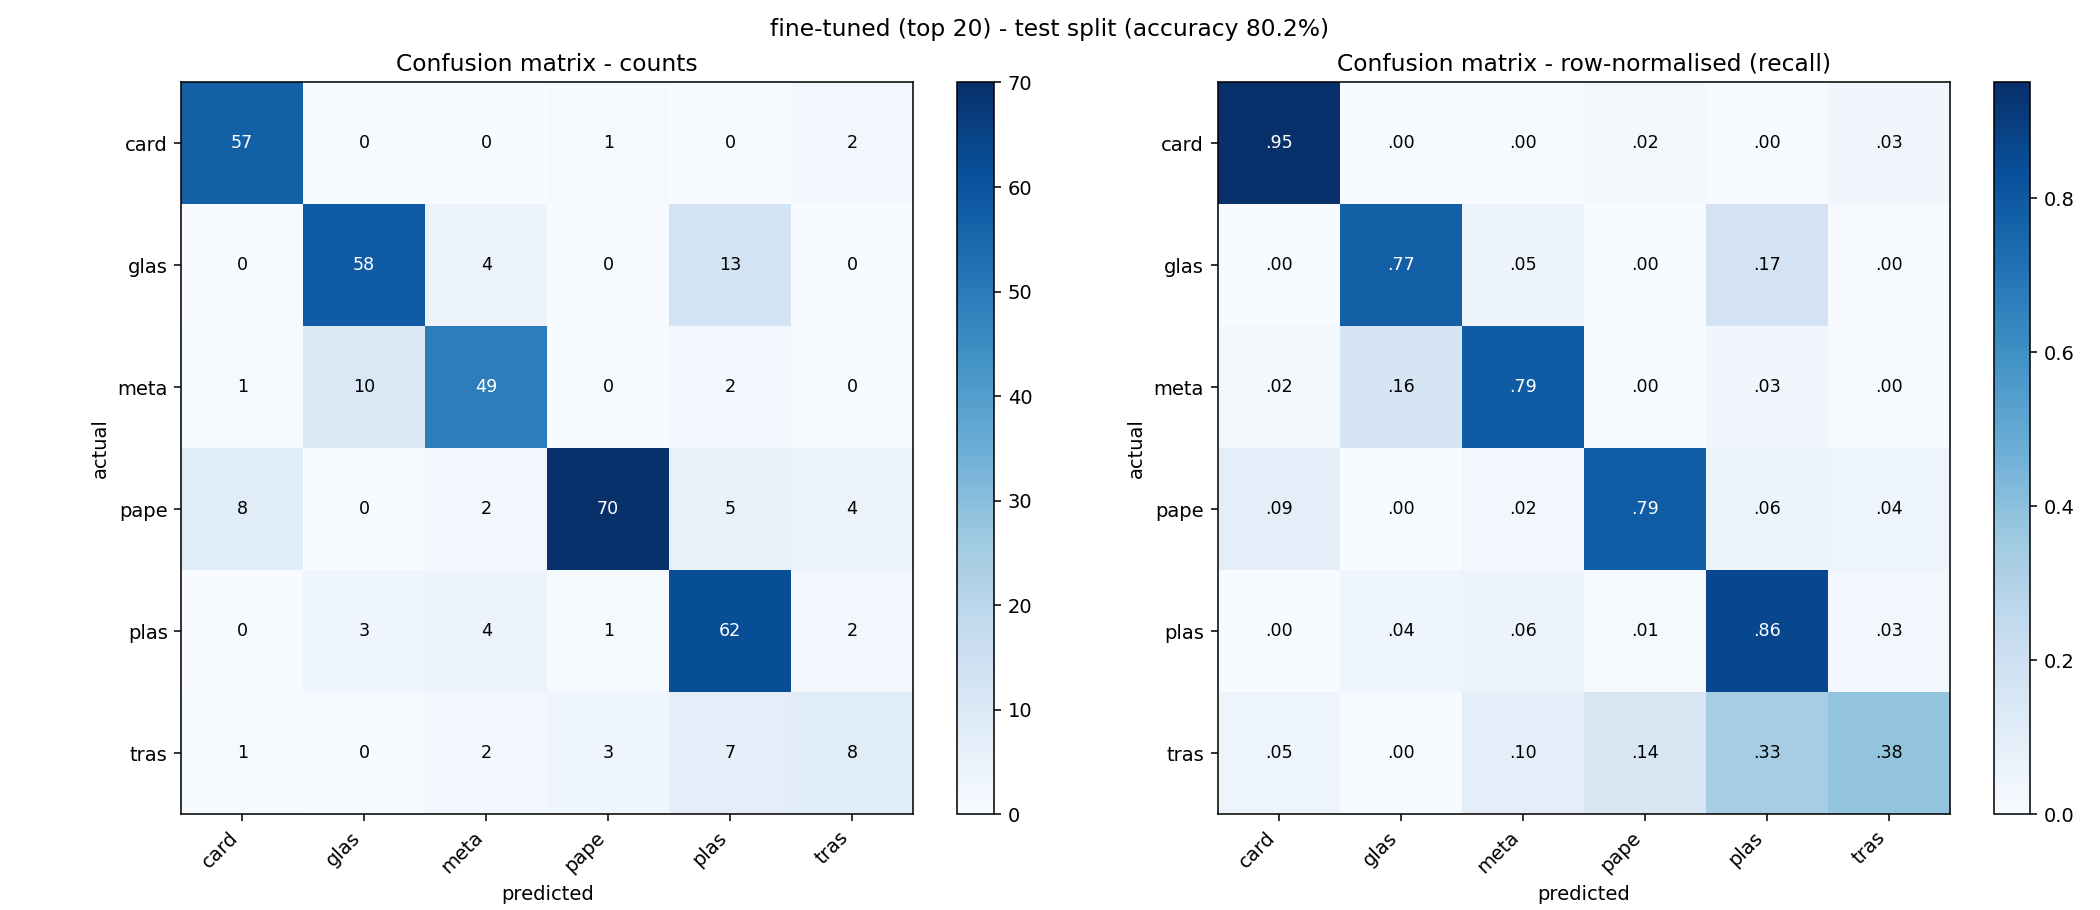

glass,plastic,13,17%
metal,glass,10,16%
paper,cardboard,8,9%
trash,plastic,7,33%
paper,plastic,5,6%
glass,metal,4,5%


  error gallery    -> d:\pengyuan9869\week2\outputs\misclassified_best.png

misclassified: 75 of 379 test images (19.8%)


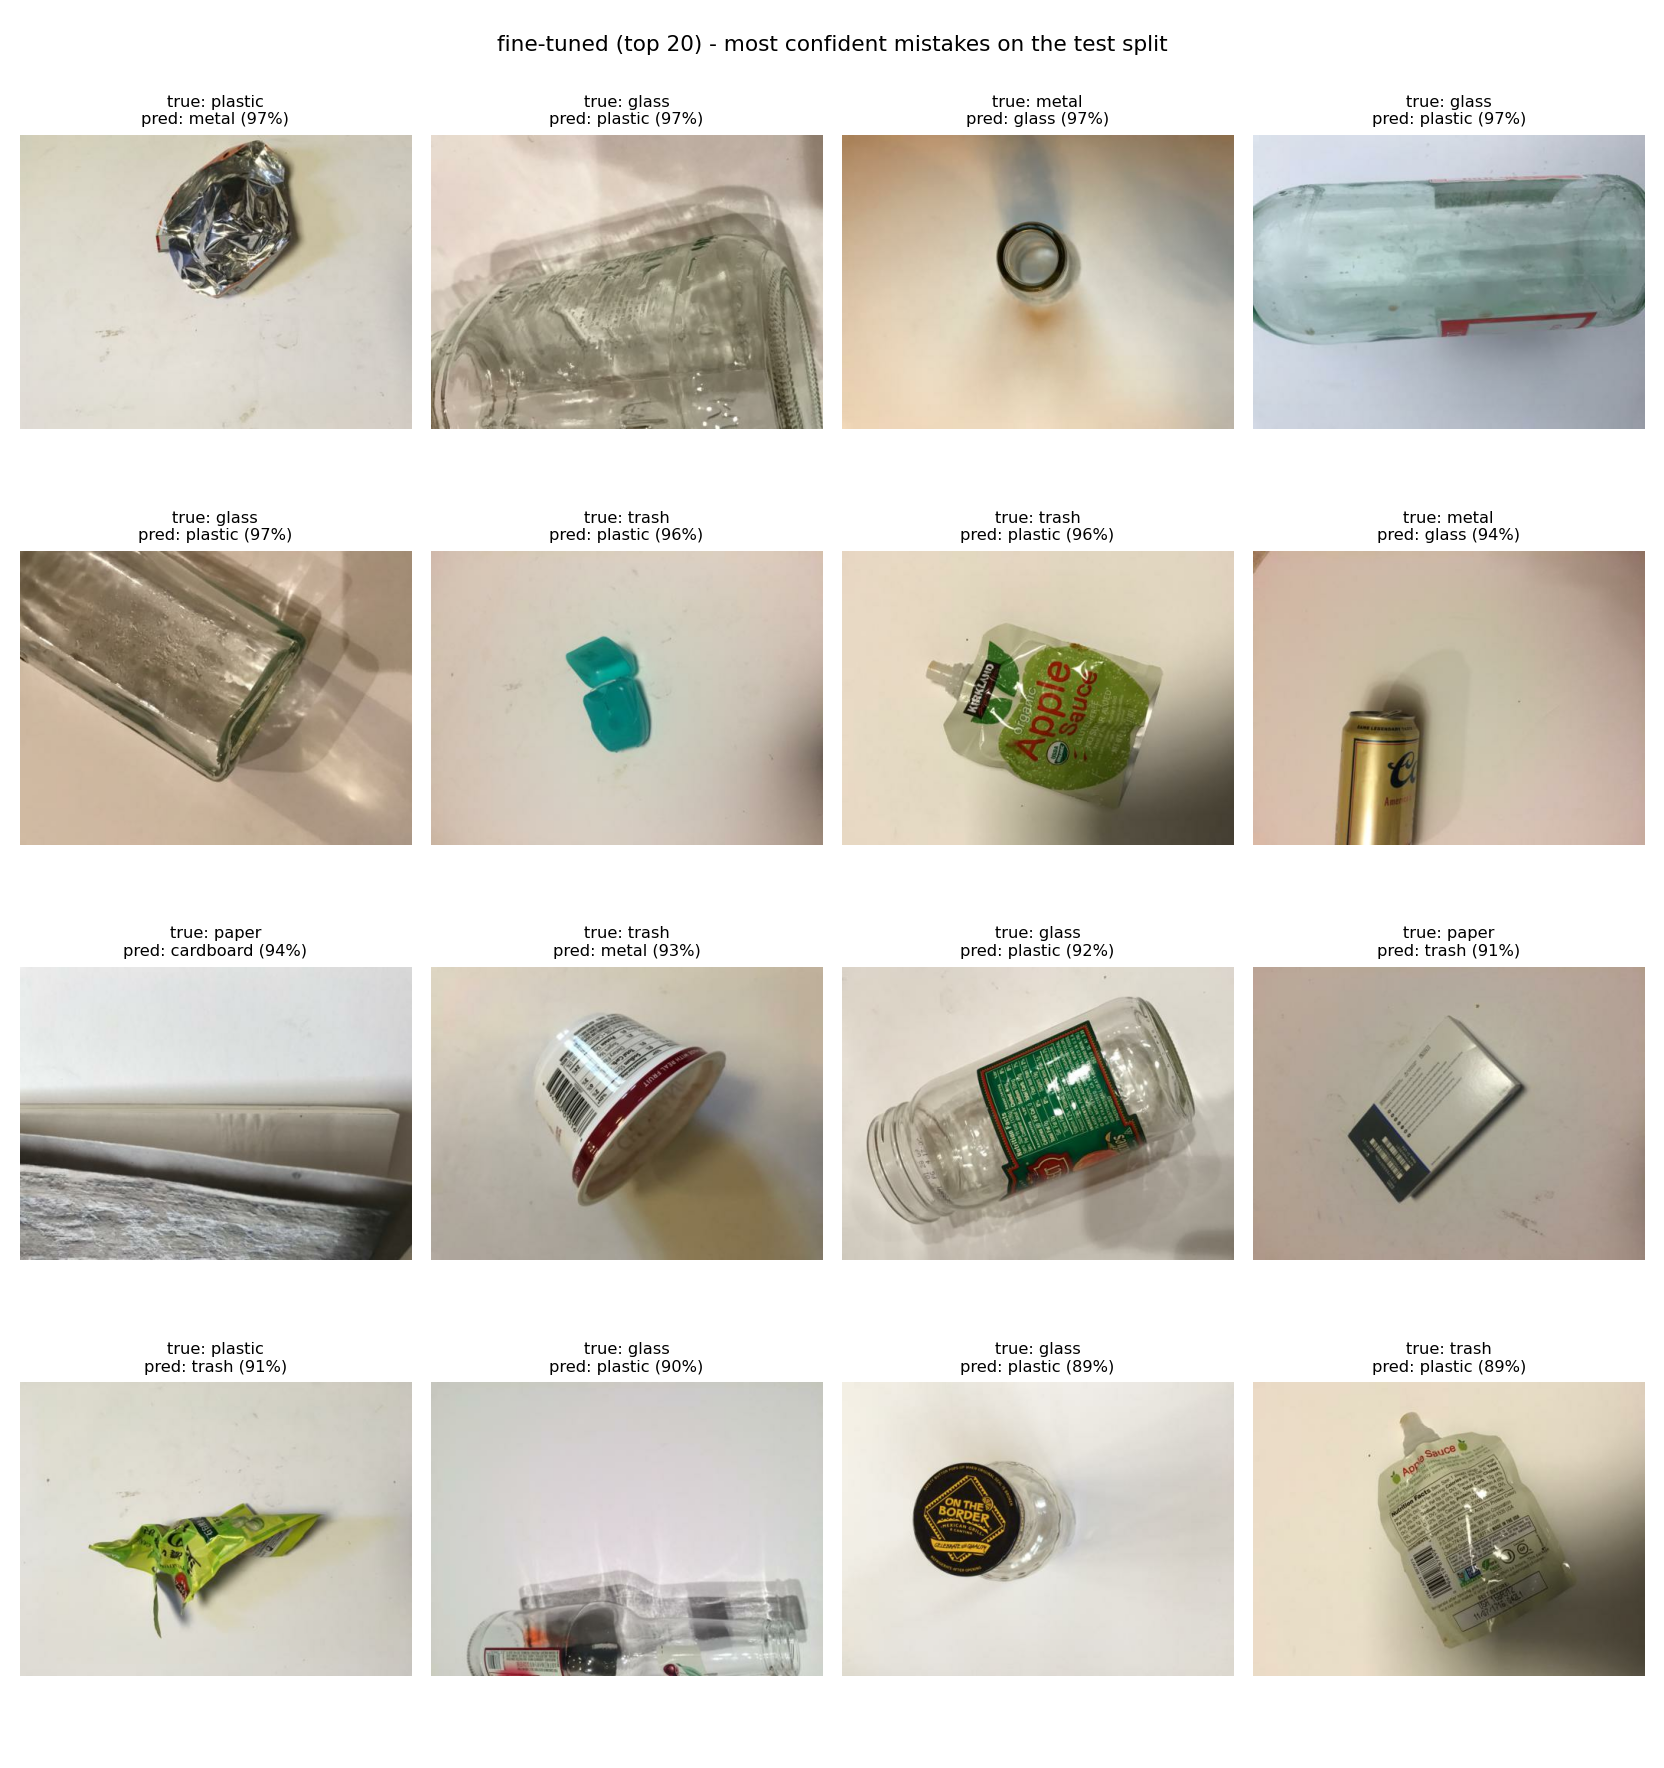

In [11]:
registered = [t for t in RESULTS if t in PROBS]
BEST_TAG = max(registered, key=lambda t: RESULTS[t]["test"]["macro_f1"])
print(f"best registered model by test macro-F1: {BEST_TAG}")

best_test = RESULTS[BEST_TAG]["test"]
y_true_best, y_prob_best = PROBS[BEST_TAG]["test"]

# `label` matters: these two plotting helpers are shared with Week 1, whose figures are
# titled after the frozen baseline. Passing the tag keeps the titles honest here and stops
# Week 2 figures from being mislabelled as Week 1's.
ev.plot_confusion(np.asarray(best_test["confusion_matrix"]),
                  OUT / "confusion_matrix_best.png", "test", best_test["accuracy"],
                  label=BEST_TAG)
show_figure(OUT / "confusion_matrix_best.png")

show_table(
    ["actual", "predicted as", "count", "% of that class"],
    [[a, p, n, f"{n / best_test['per_class'][a]['support']:.0%}"]
     for a, p, n in ev.top_confusions(np.asarray(best_test["confusion_matrix"]), k=6)],
)

n_wrong = ev.plot_misclassified(
    y_true_best, y_prob_best.argmax(axis=1), y_prob_best.max(axis=1),
    splits["test"], OUT / "misclassified_best.png", "test", label=BEST_TAG,
)
print(f"\nmisclassified: {n_wrong} of {len(splits['test'])} test images "
      f"({n_wrong / len(splits['test']):.1%})")
show_figure(OUT / "misclassified_best.png")

In [ ]:
# Targeted breakdown of the weakest class: what does it get confused with, and how often?
cm_best = np.asarray(best_test["confusion_matrix"])
weakest = min(config.CLASS_NAMES, key=lambda c: best_test["per_class"][c]["recall"])
wi = config.CLASS_NAMES.index(weakest)
support = best_test["per_class"][weakest]["support"]

print(f"weakest class on the test set: {weakest} "
      f"(recall {best_test['per_class'][weakest]['recall']:.3f}, "
      f"precision {best_test['per_class'][weakest]['precision']:.3f}, "
      f"support {support})")

show_table(
    ["it is predicted as", "count", "share of the class"],
    sorted(([config.CLASS_NAMES[j], int(cm_best[wi, j]), f"{cm_best[wi, j] / support:.0%}"]
            for j in range(config.NUM_CLASSES)),
           key=lambda row: -row[1]),
)
print()
print("Read this together with the class distribution above and the images in the gallery:")
print("the class with the fewest training images is also the one with the lowest recall, which is")
print("the imbalance story section 5 tests against - and the class itself is a catch-all 'other' category,")
print("so its members do not share a consistent visual appearance to learn from.")


weakest class on the test set: trash (recall 0.381, precision 0.500, support 21)


trash,8,38%
plastic,7,33%
paper,3,14%
metal,2,10%
cardboard,1,5%
glass,0,0%



Read this together with the class distribution above and the images in the gallery:
the class with the fewest training images is also the one with the lowest recall, which is
the imbalance story §5 tests against - and the class itself is a catch-all 'other' category,
so its members do not share a consistent visual appearance to learn from.


## 8. Conclusions

The cell below prints the Week 2 takeaways computed from the results above, so they cannot drift out
of step with what was actually measured.

The three questions posed at the top are answered as follows — with the exact figures printed by the
cell rather than repeated here, for the reason given in section 9:

1. **Fine-tuning versus the frozen baseline.** Section 4 reports both, side by side, on the shared held-out
   test set, together with the per-class change in recall *and in images*, which says which classes
   moved. The two views do not always agree, and when they disagree the per-class evidence is the one
   to trust.
2. **Class weights and the rare class.** Section 5 reports whether balancing the loss changed the rare class's
   recall, and where the matching cost landed — the trade-off is reported rather than hidden, whichever
   way it turns out.
3. **How much to unfreeze.** Section 6 ranks the configurations at 10, 20 and all, and the table shows how the
   trainable parameter count grows with depth. That is the experiment that decides whether the choice
   made in section 3 was the right one.



In [13]:
# Week 2 takeaways, computed from the results above rather than typed into markdown.
# Fixed figures in prose go stale the moment anything is retrained, because CPU
# floating-point reductions and data augmentation are not bit-reproducible.
print("RESULTS ON THE HELD-OUT TEST SET")
for t in TAGS:
    m = RESULTS[t]["test"]
    print(f"  {t:<28} accuracy {m['accuracy']:.1%}   macro-F1 {m['macro_f1']:.3f}"
          f"   errors {m['misclassified_count']:>3}/{len(splits['test'])}")

print()
print("FINE-TUNING vs BASELINE (test)")
for label, key in (("accuracy", "accuracy"), ("balanced accuracy", "balanced_accuracy"),
                   ("macro F1", "macro_f1"), ("weighted F1", "weighted_f1")):
    delta = RESULTS[FINETUNED_TAG]["test"][key] - RESULTS[BASELINE_TAG]["test"][key]
    verdict = "improved" if delta > 0.005 else ("worse" if delta < -0.005 else "unchanged")
    print(f"  {label:<18} {RESULTS[BASELINE_TAG]['test'][key]:.4f} -> "
          f"{RESULTS[FINETUNED_TAG]['test'][key]:.4f}   ({delta:+.4f}, {verdict})")

print()
print("RARE CLASS (trash) RECALL ON TEST")
for t in TAGS:
    pc = RESULTS[t]["test"]["per_class"]["trash"]
    print(f"  {t:<28} recall {pc['recall']:.3f}   precision {pc['precision']:.3f}   F1 {pc['f1']:.3f}")

if ablation_runs:
    best_ab = max(ablation_runs, key=lambda r: r["val_macro_f1"])
    print()
    print("ABLATION (short runs, ranking only)")
    for r in ablation_runs:
        print(f"  unfreeze {r['unfreeze']:<8} trainable {r['trainable_params']:>9,}"
              f"   val macro-F1 {r['val_macro_f1']:.4f}   test acc {r['test_accuracy']:.4f}")
    print(f"  best validation macro-F1 at: unfreeze {best_ab['unfreeze']}")

print()
print("REMAINING WEAK CLASS ON THE TEST SET")
for t in TAGS:
    w = min(config.CLASS_NAMES, key=lambda c: RESULTS[t]["test"]["per_class"][c]["recall"])
    print(f"  {t:<28} weakest: {w} "
          f"(recall {RESULTS[t]['test']['per_class'][w]['recall']:.3f})")

RESULTS ON THE HELD-OUT TEST SET
  baseline (frozen base)       accuracy 80.2%   macro-F1 0.768   errors  75/379
  fine-tuned (top 20)          accuracy 80.2%   macro-F1 0.758   errors  75/379
  fine-tuned + class weights   accuracy 79.2%   macro-F1 0.757   errors  79/379

FINE-TUNING vs BASELINE (test)
  accuracy           0.8021 -> 0.8021   (+0.0000, unchanged)
  balanced accuracy  0.7684 -> 0.7570   (-0.0114, worse)
  macro F1           0.7684 -> 0.7575   (-0.0109, worse)
  weighted F1        0.8025 -> 0.8004   (-0.0021, unchanged)

RARE CLASS (trash) RECALL ON TEST
  baseline (frozen base)       recall 0.476   precision 0.526   F1 0.500
  fine-tuned (top 20)          recall 0.381   precision 0.500   F1 0.432
  fine-tuned + class weights   recall 0.476   precision 0.476   F1 0.476

ABLATION (short runs, ranking only)
  unfreeze top 10   trainable   733,126   val macro-F1 0.8226   test acc 0.8047
  unfreeze top 20   trainable 1,202,566   val macro-F1 0.8168   test acc 0.8100
  unfree

### Artefacts produced by this notebook

| File | Content |
|---|---|
| `outputs/finetuned_model.keras` | Best checkpoint from the stage-two fine-tuning run |
| `outputs/finetuned_classweight_model.keras` | Best checkpoint from the class-weighted run |
| `outputs/history_finetuned.json`, `outputs/history_classweight.json` | Per-epoch metrics for both runs |
| `outputs/finetuned_log.csv`, `outputs/finetuned_classweight_log.csv` | Raw Keras CSV logs |
| `outputs/curves_finetuned.png`, `outputs/curves_classweight.png` | Training curves |
| `outputs/per_class_recall_comparison.png` | Baseline vs fine-tuned recall per class |
| `outputs/comparison.json` | All three models, val and test, in one machine-readable file |
| `outputs/confusion_matrix_best.png` | Confusion matrix of the best model on test |
| `outputs/misclassified_best.png` | Its most confident mistakes |
| `outputs/ablation_results.json`, `outputs/ablation_unfreeze_depth.png` | Unfreeze-depth ablation |
| `outputs/ablation_*_model.keras`, `outputs/ablation_*_log.csv` | Checkpoints and logs for each configuration |




## Reference list (APA 7)

Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., … Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. In *Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI '16)* (pp. 265–283). USENIX Association.

Chollet, F. (2023, June 25). *Transfer learning & fine-tuning* [Keras developer guide]. Keras. https://keras.io/guides/transfer_learning/

Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In *2009 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 248–255). IEEE.

Howard, A. G., Zhu, M., Chen, B., Kalenichenko, D., Wang, W., Weyand, T., Andreetto, M., & Adam, H. (2017). *MobileNets: Efficient convolutional neural networks for mobile vision applications*. arXiv. https://arxiv.org/abs/1704.04861

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 4510–4520). IEEE.

Thung, G. (2016). *TrashNet* [Data set]. GitHub. https://github.com/garythung/trashnet

Yang, M., & Thung, G. (2016). *Classification of trash for recyclability status* (CS229 Project Report). Stanford University. https://cs229.stanford.edu/proj2016/report/ThungYang-ClassificationOfTrashForRecyclabilityStatus-report.pdf